# in the name of allah we begin new adventure in AI

## install libraries

In [ ]:
%%capture
!pip install rdkit-pypi
!pip install torch-geometric
!pip install torch-scatter -f https://data.pyg.org/whl/torch-2.4.0+cu121.html

## Import Libraries

In [ ]:
import torch
import rdkit
from rdkit import Chem
from torch_geometric.loader import DataLoader
from IPython import display
from rdkit.Chem.Draw import IPythonConsole
import pandas
import rdkit.Chem.Lipinski as Lipinsky
from rdkit.Chem.Draw import SimilarityMaps
from rdkit import DataStructs
from rdkit.Chem import AllChem
from rdkit.Chem import Draw
from torch_geometric.utils import degree
from torch_geometric.datasets import MoleculeNet
from torch_geometric.nn import GCNConv, TopKPooling, global_mean_pool
from torch_geometric.nn import global_mean_pool, global_max_pool
from torch_geometric.typing import torch_scatter
import matplotlib.pyplot as plt
from IPython.display import clear_output
import numpy as np
import random
from torch_geometric.nn import MessagePassing, Linear, Sequential, LayerNorm, GCNConv
from torch_geometric.utils import remove_self_loops, to_dense_adj, dense_to_sparse
from torch_scatter import scatter
from torch.nn import ReLU, BatchNorm1d, Module, Sequential, InstanceNorm1d
import torch.nn.functional as F
from torch_geometric.data import InMemoryDataset

## Set random seed for deterministic results

In [ ]:
def seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed(42)

## Loading Data

In [ ]:
# Load graph dataset
dataset = MoleculeNet(root=".", name="ESOL")

# check for isolated nodes
def has_isolated_nodes(data):
    deg = degree(data.edge_index[0], data.num_nodes)
    return (deg == 0).any().item()

# Customized dataset
class GraphDataset(InMemoryDataset):
    def __init__(self, root, data_list, transform=None, pre_transform=None):
        self.data_list = data_list
        super().__init__(root, transform, pre_transform)

        self.data, self.slices = self.collate(data_list)

    def len(self):
        return len(self.data_list)

    def get(self, idx):
        return self.data_list[idx]

# filter our dataset
def filter_dataset(dataset):
    filtered_data = []
    for data in dataset:
        if data.num_nodes > 1 and not has_isolated_nodes(data):
            filtered_data.append(data)

    return GraphDataset(root=".", data_list=filtered_data)

# filtering
filtered_dataset = filter_dataset(dataset)

# Checking sizes
print(f"Original dataset size: {len(dataset)}")
print(f"Filtered dataset size: {len(filtered_dataset)}")

Processing...
Done!


Original dataset size: 1128
Filtered dataset size: 1127


In [ ]:
# our dataset is the filtered_dataset
dataset = filtered_dataset

# Investigating the dataset
print("\n================================================================")
print("Dataset type: ", type(dataset))
print("Number of graphs in the dataset: ", len(dataset))
print("Dataset features (num_features): ", dataset.num_features)
print("Dataset target classes (num_classes): ", dataset.num_classes)

# Displaying a sample graph
print("\n================================================================")
sample = dataset[0]
molecule = Chem.MolFromSmiles(sample["smiles"])
print("Sample graph:")
print("Number of nodes (atoms): ", sample.num_nodes)
print("Number of edges (bonds): ", sample.num_edges)
print("Node features shape: ", sample.x.shape)
print("Edge index shape (graph connections): ", sample.edge_index.shape)
print("Graph label: ", sample.y, type(sample.y))

# Displaying detailed node and edge information for the sample
print("\n================================================================")
print("Sample node features (first 5 nodes):\n", sample.x[:5])
print("Sample edge index (first 5 edges):\n", sample.edge_index[:, :5])

# Optionally, display SMILES if it's part of the dataset
print("\n================================================================")
if hasattr(sample, 'smiles'):
    print("SMILES representation of the molecule: ", sample.smiles)



Dataset type:  <class '__main__.GraphDataset'>
Number of graphs in the dataset:  1127
Dataset features (num_features):  9
Dataset target classes (num_classes):  733

Sample graph:
Number of nodes (atoms):  32
Number of edges (bonds):  68
Node features shape:  torch.Size([32, 9])
Edge index shape (graph connections):  torch.Size([2, 68])
Graph label:  tensor([[-0.7700]]) <class 'torch.Tensor'>

Sample node features (first 5 nodes):
 tensor([[8, 0, 2, 5, 1, 0, 4, 0, 0],
        [6, 0, 4, 5, 2, 0, 4, 0, 0],
        [6, 0, 4, 5, 1, 0, 4, 0, 1],
        [8, 0, 2, 5, 0, 0, 4, 0, 1],
        [6, 0, 4, 5, 1, 0, 4, 0, 1]])
Sample edge index (first 5 edges):
 tensor([[0, 1, 1, 2, 2],
        [1, 0, 2, 1, 3]])

SMILES representation of the molecule:  OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)C(O)C3O 


/usr/local/lib/python3.10/dist-packages/torch_geometric/data/dataset.py:169: UserWarning: Found floating-point labels while calling `dataset.num_classes`. Returning the number of unique elements. Please make sure that this is expected before proceeding.
  warnings.warn("Found floating-point labels while calling "


In [ ]:
print("Edges in COO format (source node -> target node):")
print(sample.edge_index.t().shape)
print(sample.num_edges)

type(molecule)

Edges in COO format (source node -> target node):
torch.Size([68, 2])
68


rdkit.Chem.rdchem.Mol

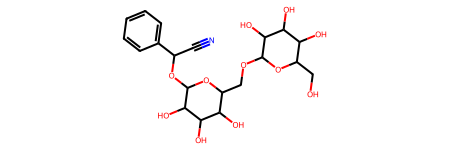

In [ ]:
molecule

## Hyperparameters

In [ ]:
data_size = len(dataset)
train_size = int(data_size * 0.8)
test_size = int(data_size * 0.1)
val_size = data_size - train_size - test_size  # Remainder for validation

b_size = 64
epochs = 10000
lr = 0.0005
drop_rate = 0.0
n_mpnn = 6        # Number of message passing layers
i_dim = 9         # Input node feature dimension (should match the data)
o_dim = 1         # Output dimension
hh_emb = 32       # Hidden node embedding dimension
he_emb = 3        # Edge feature dimension (should match the data)

In [ ]:
print(f"testing data size: {test_size}")
print(f"validation data size: {val_size}")
print(f"training data size: {train_size}")

testing data size: 112
validation data size: 114
training data size: 901


## Data Loaders

In [ ]:
train_loader = DataLoader(dataset[:train_size],
                          batch_size=b_size, shuffle=True)
val_loader = DataLoader(dataset[train_size: train_size+val_size],
                        batch_size=b_size, shuffle=True)
test_loader = DataLoader(dataset[train_size+val_size:],
                         batch_size=b_size, shuffle=True)

In [ ]:
for mol in train_loader:
    x, y = mol.x, mol.y
    print(x.shape, y.shape)
    break

torch.Size([887, 9]) torch.Size([64, 1])


In [ ]:
# Train Loader
for i, batch in enumerate(train_loader):
    x, y, e_idx, e_attr, b_idx = batch.x.float(), batch.y.float(), batch.edge_index, batch.edge_attr, batch.batch

    # Check node count matches
    if x.shape[0] != b_idx.shape[0]:
        print(f"Train Loader - Batch {i} Node Count Mismatch!")
        print(f"x.shape[0]: {x.shape[0]}, b_idx.shape[0]: {b_idx.shape[0]}")

    # Check edge count matches
    if e_idx.shape[1] != e_attr.shape[0]:
        print(f"Train Loader - Batch {i} Edge Count Mismatch!")
        print(f"e_idx.shape[1]: {e_idx.shape[1]}, e_attr.shape[0]: {e_attr.shape[0]}")

# Val Loader
for i, batch in enumerate(val_loader):
    x, y, e_idx, e_attr, b_idx = batch.x.float(), batch.y.float(), batch.edge_index, batch.edge_attr, batch.batch

    if x.shape[0] != b_idx.shape[0]:
        print(f"Val Loader - Batch {i} Node Count Mismatch!")
        print(f"x.shape[0]: {x.shape[0]}, b_idx.shape[0]: {b_idx.shape[0]}")

    if e_idx.shape[1] != e_attr.shape[0]:
        print(f"Val Loader - Batch {i} Edge Count Mismatch!")
        print(f"e_idx.shape[1]: {e_idx.shape[1]}, e_attr.shape[0]: {e_attr.shape[0]}")

# Test Loader
for i, batch in enumerate(test_loader):
    x, y, e_idx, e_attr, b_idx = batch.x.float(), batch.y.float(), batch.edge_index, batch.edge_attr, batch.batch

    if x.shape[0] != b_idx.shape[0]:
        print(f"Test Loader - Batch {i} Node Count Mismatch!")
        print(f"x.shape[0]: {x.shape[0]}, b_idx.shape[0]: {b_idx.shape[0]}")

    if e_idx.shape[1] != e_attr.shape[0]:
        print(f"Test Loader - Batch {i} Edge Count Mismatch!")
        print(f"e_idx.shape[1]: {e_idx.shape[1]}, e_attr.shape[0]: {e_attr.shape[0]}")


## Helpers

In [ ]:
# # Initialize variables to store the problematic batch and error information
# problematic_batch = None
# error_details = None
# f_batch = None

# for i in range(10000):
#     model.eval()
#     with torch.no_grad():
#         for batch_idx, batch in enumerate(val_loader):
#             try:
#                 x, y, e_idx = batch.x.float(), batch.y.float(), batch.edge_index
#                 e_attr, b_idx = batch.edge_attr, batch.batch

#                 # Forward pass
#                 pred = model(x=x, e_idx=e_idx, e_attr=e_attr, b_idx=b_idx)

#             except Exception as e:
#                 f_batch = batch
#                 problematic_batch = {
#                     'batch_idx': batch_idx,
#                     'x': x,
#                     'y': y,
#                     'e_idx': e_idx,
#                     'e_attr': e_attr,
#                     'b_idx': b_idx
#                 }
#                 error_details = str(e)
#                 print(f"Error encountered in epoch {i}, batch {batch_idx}: {error_details}")
#                 break
#         if problematic_batch:
#             break

# num_nodes = f_x.size(0)
# edge_sources = f_e_idx[0]
# edge_targets = f_e_idx[1]

# connected_nodes = torch.cat([edge_sources, edge_targets]).unique()

# all_nodes = torch.arange(num_nodes, device=f_x.device)

# isolated_mask = ~torch.isin(all_nodes, connected_nodes)
# isolated_nodes = all_nodes[isolated_mask]

# if isolated_nodes.numel() > 0:
#     print(f"There is/are {isolated_nodes.numel()} isolated node(s): {isolated_nodes}")
# else:
#     print("There are no isolated nodes. All nodes are connected to at least one other node.")

In [ ]:
def live_plot(train_losses, val_losses, train_maes, val_maes, train_mses, val_mses, train_rmses, val_rmses, train_r2s, val_r2s):
    clear_output(wait=True)

    plt.figure(figsize=(12, 6))

    # Plot training metrics
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Train Loss', color='blue')
    plt.plot(train_maes, label='Train MAE', color='green')
    plt.plot(train_mses, label='Train MSE', color='red')
    plt.plot(train_rmses, label='Train RMSE', color='purple')
    plt.plot(train_r2s, label='Train R²', color='brown')
    plt.xlabel('Epoch')
    plt.ylabel('Value')
    plt.title('Training Metrics')
    plt.legend()
    plt.grid(True)

    # Plot validation metrics
    plt.subplot(1, 2, 2)
    plt.plot(val_losses, label='Validation Loss', color='blue')
    plt.plot(val_maes, label='Validation MAE', color='green')
    plt.plot(val_mses, label='Validation MSE', color='red')
    plt.plot(val_rmses, label='Validation RMSE', color='purple')
    plt.plot(val_r2s, label='Validation R²', color='brown')
    plt.xlabel('Epoch')
    plt.ylabel('Value')
    plt.title('Validation Metrics')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()


def compute_metrics(x, y):
    # Convert x and y to tensors if they aren't already
    x = torch.tensor(x) if not isinstance(x, torch.Tensor) else x
    y = torch.tensor(y) if not isinstance(y, torch.Tensor) else y

    # Mean Absolute Error
    mae = torch.mean(torch.abs(x - y)).item()

    # Mean Squared Error
    mse = torch.mean((x - y) ** 2)

    # Root Mean Squared Error
    rmse = torch.sqrt(mse).item()

    # R-squared
    mean_y = torch.mean(y)
    ss_total = torch.sum((y - mean_y) ** 2)
    ss_residual = torch.sum((y - x) ** 2)
    r2 = 1 - (ss_residual / ss_total).item()

    return mae, mse.item(), rmse, r2

def trainer(model, loader):
    model.train()
    total_loss = 0
    all_preds = []
    all_targets = []

    for batch in loader:
        x, y, e_idx = batch.x.float().to(device), batch.y.float().to(device), batch.edge_index.to(device)
        e_attr, b_idx =  batch.edge_attr.to(device), batch.batch.to(device)

        # Extremely Important
        optimizer.zero_grad()

        # Forward pass
        pred = model(x=x, e_idx=e_idx, e_attr=e_attr, b_idx=b_idx)

        # loss
        loss = loss_fn(pred.squeeze(), y.squeeze())
        total_loss += loss.item()

        # Backward pass
        loss.backward()
        optimizer.step()

        # Collect predictions and targets for metrics calculation
        all_preds.append(pred.cpu().detach())
        all_targets.append(y.cpu().detach())

    avg_loss = total_loss / len(loader)

    # Concatenate all predictions and targets
    all_preds = torch.cat(all_preds)
    all_targets = torch.cat(all_targets)

    # Compute metrics
    mae, mse, rmse, r2 = compute_metrics(all_preds, all_targets)

    return avg_loss, mae, mse, rmse, r2

def validator(model, loader):
    model.eval()
    total_loss = 0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for batch in loader:
            x, y, e_idx = batch.x.float().to(device), batch.y.float().to(device), batch.edge_index.to(device)
            e_attr, b_idx =  batch.edge_attr.to(device), batch.batch.to(device)

            # Forward pass
            pred = model(x=x, e_idx=e_idx, e_attr=e_attr, b_idx=b_idx)

            # Calculate loss
            loss = loss_fn(pred.squeeze(), y.squeeze())
            total_loss += loss.item()

            # Collect predictions and targets for metrics calculation
            all_preds.append(pred.cpu().detach())
            all_targets.append(y.cpu().detach())

    avg_loss = total_loss / len(loader)

    # Concatenate all predictions and targets
    all_preds = torch.cat(all_preds)
    all_targets = torch.cat(all_targets)

    # Compute metrics
    mae, mse, rmse, r2 = compute_metrics(all_preds, all_targets)

    return avg_loss, mae, mse, rmse, r2

In [ ]:
def permute_g(data, p):
    # Permute node attributes
    data.x = data.x[p]
    data.batch = data.batch[p]

    # Permute edge index
    adj = to_dense_adj(data.edge_index)
    adj = adj[:, p, :]
    adj = adj[:, :, p]
    data.edge_index, _ = dense_to_sparse(adj)

    return data

def perm_invariance_test(mpnn, loader):
    it = iter(loader)
    data = next(it)

    data.edge_attr = torch.zeros(data.edge_attr.shape) # dummy values for simplicity
    x, y, e_idx, e_attr, b_idx = data.x.float(), data.y.float(), data.edge_index, data.edge_attr, data.batch
    out1 = mpnn(x=x, e_idx=e_idx, e_attr=e_attr)

    # random perm
    p = torch.randperm(data.x.shape[0])
    data = permute_g(data, p)
    x, y, e_idx, e_attr, b_idx = data.x.float(), data.y.float(), data.edge_index, data.edge_attr, data.batch
    out2 = mpnn(x=x, e_idx=e_idx, e_attr=e_attr)

    # Check invariance
    return torch.allclose(out1, out2, atol=1e-04)

def perm_equivariance_test(model, loader):
    it = iter(loader)
    data = next(it)

    # Set edge_attr to dummy values
    data.edge_attr = torch.zeros(data.edge_attr.shape)
    x, y, e_idx, e_attr, b_idx = data.x.float(), data.y.float(), data.edge_index, data.edge_attr, data.batch
    out1 = model(x=x, e_idx=e_idx, e_attr=e_attr, b_idx=b_idx)

    # Create random permutation
    p = torch.randperm(data.x.shape[0])
    data = permute_g(data, p)
    x, y, e_idx, e_attr, b_idx = data.x.float(), data.y.float(), data.edge_index, data.edge_attr, data.batch
    out2 = model(x=x, e_idx=e_idx, e_attr=e_attr, b_idx=b_idx)

    return torch.allclose(out1, out2, atol=1e-04)

## building model

In [ ]:
class MPNN(MessagePassing):
    def __init__(self, hh_emb, he_emb, aggr='mean'):
        super().__init__(aggr=aggr)

        self.hh_emb = hh_emb
        self.he_emb = he_emb

        # MESSAGE NETWORK: mij = M(hi, hj, eij)
        self.msg_net = Sequential(
            # [b_size, n_node, 2*hh_emb + he_emb] ==> [b_size, n_node, hh_emb]
            Linear(2*hh_emb + he_emb, hh_emb),
            LayerNorm(hh_emb), # InstanceNorm1d(hh_emb), # BatchNorm1d(hh_emb),
            ReLU(),
            # [b_size, n_node, hh_emb] ==> [b_size, n_node, hh_emb]
            Linear(hh_emb, hh_emb),
            LayerNorm(hh_emb), # InstanceNorm1d(hh_emb), # BatchNorm1d(hh_emb),
            ReLU(),
          )

        # UPDATE NETWORK: hi = U(hi, aggr(mij))
        self.upd_net = Sequential(
            # [b_size * num_nodes, 2*hh_emb] ==> [b_size * num_nodes, hh_emb]
            Linear(2*hh_emb, hh_emb),
            LayerNorm(hh_emb), # InstanceNorm1d(hh_emb), # BatchNorm1d(hh_emb),
            ReLU(),
            # [b_size * num_nodes, hh_emb] ==> [b_size * num_nodes, hh_emb]
            Linear(hh_emb, hh_emb),
            LayerNorm(hh_emb), # InstanceNorm1d(hh_emb), # BatchNorm1d(hh_emb),
            ReLU(),
          )

    def forward(self, x, e_idx, e_attr=None):
        # propagate() <==> message() -> aggregate() -> update()
        # [b_size, num_nodes, hh_emb] ==> [b_size, num_nodes, hh_emb]
        out = self.propagate(edge_index=e_idx, h=x, edge_attr=e_attr)
        return out

    def message(self, h_i, h_j, edge_attr=None):
        # mij = M(hi, hj, eij): [b_size, n_node, 2*hh_emb + he_emb] ==> [b_size, n_node, hh_emb]
        if edge_attr is None:
            mij = torch.cat([h_i, h_j], dim=-1)
        else:
            mij = torch.cat([h_i, h_j, edge_attr], dim=-1)
        mij = self.msg_net(mij)
        return mij

    def aggregate(self, inputs, index):
        # h_aggr = Σ/mean/max/min(mij)
        print(f"self.node_dim: [{self.node_dim}], inputs.shape: {inputs.shape}, index.shape: {index.shape}]")
        h_aggr = scatter(inputs, index, dim=0, reduce=self.aggr)
        return h_aggr

    def update(self, h_aggr, h):
        # h_new = U(h_aggr, h) : [b_size, n_node, hh_emb], [b_size, n_node, hh_emb]
        h_new = torch.cat([h, h_aggr], dim=-1)
        h_new = self.upd_net(h_new)
        return h_new

    def __repr__(self) -> str:
        return (f'{self.__class__.__name__}(hh_emb={self.hh_emb}, aggr={self.aggr})')

In [ ]:
class MPNNModel(Module):
    def __init__(self, n_mpnn, i_dim, o_dim, hh_emb, he_emb, aggr="sum"):
        """
        n_mpnn (int): Number of message passing layers `L`.
        hh_emb (int): Hidden dimension `d`.
        i_dim (int): Input node feature dimension `d_n`.
        he_emb (int): Edge feature dimension `d_e`.
        o_dim (int): Output dimension (default is 1).
        """
        super().__init__()
        self.n_mpnn = n_mpnn
        self.hh_emb = hh_emb
        self.he_emb = he_emb
        self.aggr = aggr

        # [b_size, i_dim] ==> [b_size, hh_emb]
        self.ln1 = Linear(i_dim, hh_emb)

        # multiple MPNN layers
        self.mpnns = torch.nn.ModuleList()
        for _ in range(n_mpnn):
            self.mpnns.append(MPNN(hh_emb=hh_emb, he_emb=he_emb, aggr=self.aggr))

        # Global mean pooling
        self.gmp = global_mean_pool

        # [b_size, hh_emb] ==> [b_size, o_dim]
        self.ln2 = Linear(hh_emb, o_dim)

    def forward(self, x, e_idx, e_attr, b_idx):
        # [b_size, n_node, i_dim] ==> [b_size, n_node, hh_emb]
        x = self.ln1(x)

        # MPNN + res connect: [b_size, n_node, hh_emb] ==> [b_size, n_node, hh_emb]
        for mpnn in self.mpnns:
            x = x + mpnn(x=x, e_idx=e_idx, e_attr=e_attr)

        # global mean pooling: [b_size, n_node, hh_emb] ==> [b_size, hh_emb]
        x = self.gmp(x, b_idx)

        # [b_size, hh_emb] ==> [b_size, o_dim]
        logits = self.ln2(x)
        return logits

In [ ]:
# Define model parameters
model = MPNNModel(n_mpnn=n_mpnn, i_dim=i_dim, o_dim=o_dim, hh_emb=hh_emb, he_emb=he_emb)

print("Model Summary:")
print(model)

for i, batch in enumerate(val_loader):
    x, y, e_idx, e_attr, b_idx = batch.x.float(), batch.y.float(), batch.edge_index, batch.edge_attr, batch.batch

    if i == 0:
      print("\nData Info:")
      print(f"{'Variable':<10} {'Type':<20} {'Shape'}")
      print(f"{'-'*40}")
      print(f"{'x':<10} {str(type(x)):<20} {x.shape}")
      print(f"{'y':<10} {str(type(y)):<20} {y.shape}")
      print(f"{'e_idx':<10} {str(type(e_idx)):<20} {e_idx.shape}")
      print(f"{'e_attr':<10} {str(type(e_attr)):<20} {e_attr.shape}")
      print(f"{'b_idx':<10} {str(type(b_idx)):<20} {b_idx.shape}\n")

    logits = model(x=x, e_idx=e_idx, e_attr=e_attr, b_idx=b_idx)

    print(f"logits: {logits.shape}")
    break

Model Summary:
MPNNModel(
  (ln1): Linear(9, 32, bias=True)
  (mpnns): ModuleList(
    (0-5): 6 x MPNN(hh_emb=32, aggr=sum)
  )
  (ln2): Linear(32, 1, bias=True)
)

Data Info:
Variable   Type                 Shape
----------------------------------------
x          <class 'torch.Tensor'> torch.Size([964, 9])
y          <class 'torch.Tensor'> torch.Size([64, 1])
e_idx      <class 'torch.Tensor'> torch.Size([2, 2006])
e_attr     <class 'torch.Tensor'> torch.Size([2006, 3])
b_idx      <class 'torch.Tensor'> torch.Size([964])

self.node_dim: [-2], inputs.shape: torch.Size([2006, 32]), index.shape: torch.Size([2006])]
self.node_dim: [-2], inputs.shape: torch.Size([2006, 32]), index.shape: torch.Size([2006])]
self.node_dim: [-2], inputs.shape: torch.Size([2006, 32]), index.shape: torch.Size([2006])]
self.node_dim: [-2], inputs.shape: torch.Size([2006, 32]), index.shape: torch.Size([2006])]
self.node_dim: [-2], inputs.shape: torch.Size([2006, 32]), index.shape: torch.Size([2006])]
self.node_d

## Sanity Check for our Graph Model

In [ ]:
mpnn = MPNN(hh_emb=9, he_emb=3)
model = MPNNModel(n_mpnn=6, i_dim=9, o_dim=1, hh_emb=9, he_emb=3, aggr="mean")
loader = DataLoader(dataset=dataset[:10], batch_size=1)

# test
print(f"Is {type(model).__name__} permutation invariant? --> {perm_invariance_test(mpnn, loader)}!")
print(f"Is {type(mpnn).__name__} permutation equivariant? --> {perm_equivariance_test(model, loader)}!")

self.node_dim: [-2], inputs.shape: torch.Size([68, 9]), index.shape: torch.Size([68])]
self.node_dim: [-2], inputs.shape: torch.Size([68, 9]), index.shape: torch.Size([68])]
Is MPNNModel permutation invariant? --> False!
self.node_dim: [-2], inputs.shape: torch.Size([68, 9]), index.shape: torch.Size([68])]
self.node_dim: [-2], inputs.shape: torch.Size([68, 9]), index.shape: torch.Size([68])]
self.node_dim: [-2], inputs.shape: torch.Size([68, 9]), index.shape: torch.Size([68])]
self.node_dim: [-2], inputs.shape: torch.Size([68, 9]), index.shape: torch.Size([68])]
self.node_dim: [-2], inputs.shape: torch.Size([68, 9]), index.shape: torch.Size([68])]
self.node_dim: [-2], inputs.shape: torch.Size([68, 9]), index.shape: torch.Size([68])]
self.node_dim: [-2], inputs.shape: torch.Size([68, 9]), index.shape: torch.Size([68])]
self.node_dim: [-2], inputs.shape: torch.Size([68, 9]), index.shape: torch.Size([68])]
self.node_dim: [-2], inputs.shape: torch.Size([68, 9]), index.shape: torch.Size([68

## Init Model, Loss, Optimizer ...

In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = MPNNModel(n_mpnn=n_mpnn, i_dim=i_dim, o_dim=o_dim, hh_emb=hh_emb, he_emb=he_emb).to(device)
loss_fn = torch.nn.MSELoss(reduction='mean')
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

## Train the Model

KeyboardInterrupt: 

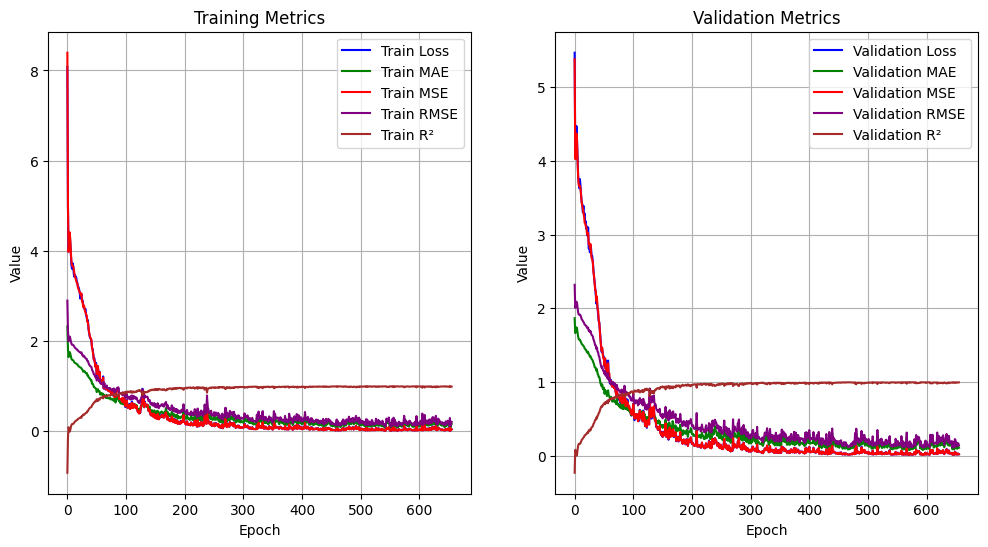

In [ ]:
# Initialize lists to store metrics
train_losses = []
val_losses = []
train_maes = []
val_maes = []
train_mses = []
val_mses = []
train_rmses = []
val_rmses = []
train_r2s = []
val_r2s = []

print("Starting training...")

# Run training for a specified number of epochs
for epoch in range(epochs):
    # Training phase
    tr_loss, tr_mae, tr_mse, tr_rmse, tr_r2 = trainer(model, val_loader)
    clear_output(wait=True)
    train_losses.append(tr_loss)
    train_maes.append(tr_mae)
    train_mses.append(tr_mse)
    train_rmses.append(tr_rmse)
    train_r2s.append(tr_r2)

    # Validation phase
    val_loss, val_mae, val_mse, val_rmse, val_r2 = validator(model, val_loader)
    val_losses.append(val_loss)
    val_maes.append(val_mae)
    val_mses.append(val_mse)
    val_rmses.append(val_rmse)
    val_r2s.append(val_r2)

    # Plot live metrics
    live_plot(train_losses, val_losses, train_maes, val_maes, train_mses, val_mses, train_rmses, val_rmses, train_r2s, val_r2s)